<a href="https://colab.research.google.com/github/baektaehee1026-ui/26-2-DIP-Baektaehee-202401846-/blob/main/HW05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [3]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive'

Mounted at /content/drive


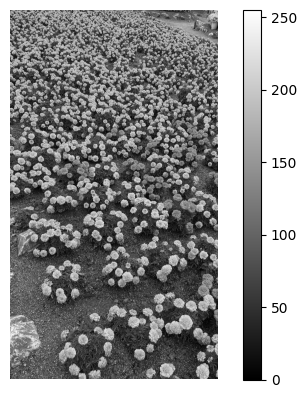

In [4]:
I = Image.open(imgpath+'/myphoto1105.jpg').convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

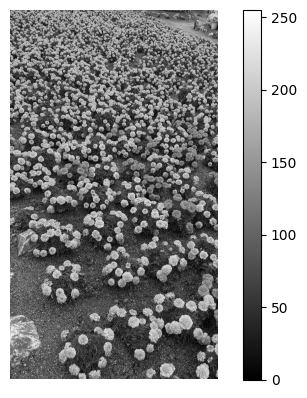

In [5]:
f_denoised = signal.medfilt2d(f,3)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

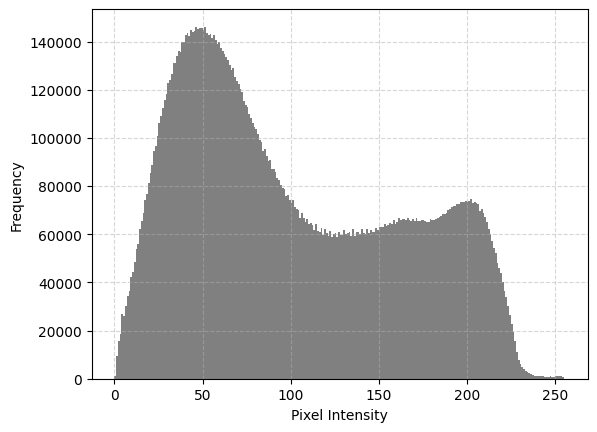

In [6]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

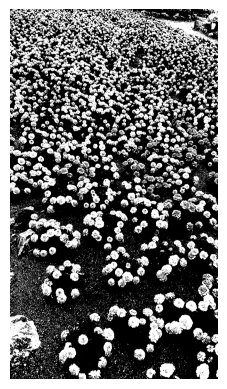

In [8]:
th_val = 128
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

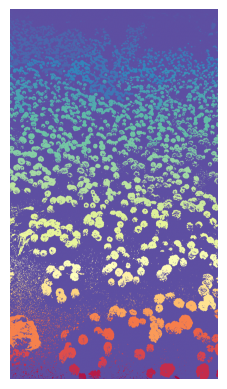

In [ ]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [ ]:
cc = np.zeros((nums-1,2))
for i in range(1,nums):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

Streaming output truncated to the last 5000 lines.
index: 1727, number of pixels: 111
index: 1728, number of pixels: 14
index: 1729, number of pixels: 5611
index: 1730, number of pixels: 474
index: 1731, number of pixels: 31
index: 1732, number of pixels: 4
index: 1733, number of pixels: 17
index: 1734, number of pixels: 16
index: 1735, number of pixels: 12498
index: 1736, number of pixels: 7
index: 1737, number of pixels: 28
index: 1738, number of pixels: 3
index: 1739, number of pixels: 19
index: 1740, number of pixels: 39
index: 1741, number of pixels: 32
index: 1742, number of pixels: 13
index: 1743, number of pixels: 123
index: 1744, number of pixels: 23941
index: 1745, number of pixels: 12
index: 1746, number of pixels: 148
index: 1747, number of pixels: 25
index: 1748, number of pixels: 22
index: 1749, number of pixels: 16
index: 1750, number of pixels: 1
index: 1751, number of pixels: 1717
index: 1752, number of pixels: 76
index: 1753, number of pixels: 7
index: 1754, number of

In [ ]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(ind_max)}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(ind_min)}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 0, # of pixels: 667885
the smallest component: index 47, # of pixels: 1


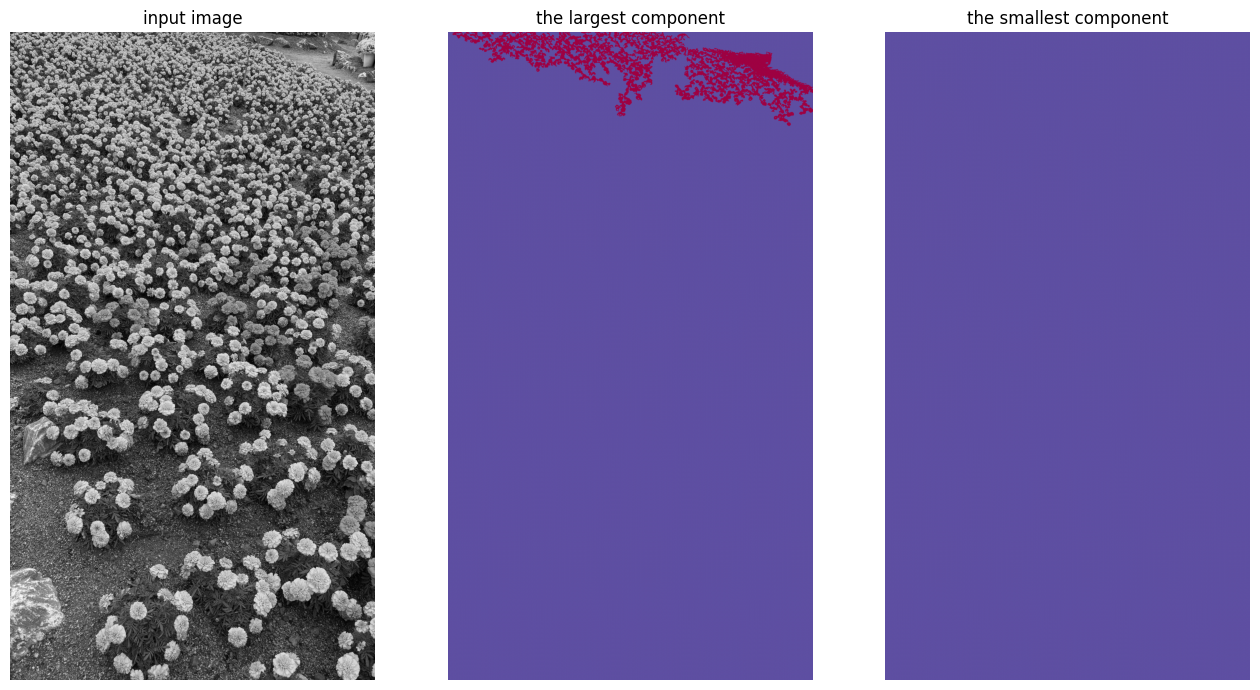

In [ ]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()
#smallest component는 왜 안 보이는걸까... -> 픽셀 수가 너무 적어서 눈에 안 띄는 경우 !!
